# AAAIM Evaluation Test

This notebook tests both single model evaluation and batch evaluation of multiple models.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
from pathlib import Path
import logging
import warnings
warnings.filterwarnings('ignore')

# Add the project root to the Python path
project_root = Path().absolute().parent
sys.path.insert(0, str(project_root))

# Import AAAIM functions
from core import annotate_model, curate_model
from core.database_search import force_clear_chromadb, get_species_recommendations_rag
from utils.evaluation import (
    evaluate_single_model,
    evaluate_models_in_folder,
    print_evaluation_results,
    compare_results,
    process_saved_llm_responses
)

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

# LLM configuration
llm_model = "gpt-5-mini-2025-08-07"
# llm_model = "Llama-4-Maverick-17B-128E-Instruct-FP8"
# llm_model = "Llama-3.3-70B-Instruct"
# llm_model = "meta-llama/llama-3.3-70b-instruct:free"
# llm_model = "gpt-4.1-nano"

# Evaluation parameters
max_entities_per_model = 10  # Limit entities per model for testing
num_models_to_test = 5  # Number of models to test in batch evaluation

# Entity and database configuration
entity_type = "chemical"
database = "chebi"

output_dir = "./results/"  # Output directory for results

### Test function

In [3]:
model_file="/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels_251106/BIOMD0000000088.xml"
from utils.evaluation import find_species_with_formulas
existing_annotations = find_species_with_formulas(model_file, ['is','isVersionOf','hasPart'])
from core.model_info import format_prompt
prompt = format_prompt(model_file, existing_annotations[0].keys(), 'chemical')
print(prompt)

Now annotate these:
Chemical to annotate: s165, s48, s187, s50, s173, s153, s152, s214, s151, s231, s252, s279, s280, s311, s135, s172, s430, s432, s436, s438, s439, s440, s443, s444, s446, s449, s456, s506, s512, s513, s520, s526, s539, s546, s551, s556, s267, s557, s564, s565, s566, s567, s568, s569
Model: "Maeda2006_MyosinPhosphorylation"
// Display Names:
s276:"CaM"; s539:"MLCK.2Ca_super_2_plus__endsuper_.CaM.MLC"; s280:"4Ca_super_2_plus__endsuper_.CaM"; s421:"G_beta__gamma__2"; s410:"G_beta__gamma__1"; s231:"Rho.GDP"; s118:"RhoGAP"; s512:"MLCK.3Ca_super_2_plus__endsuper_.CaM.MLC"; s187:"G_sub_q_endsub__alpha_.GTP"; s564:"PLC_beta_.G_sub_q_endsub__alpha_.GTP.Ca_super_2_plus__endsuper_"; s165:"Inositol"; s449:"Rho.GTP.Rho-kinase.MLC"; s556:"Ca_super_2_plus__endsuper_ ext leak"; s50:"GDP"; s267:"Ca_super_2_plus__endsuper_ ext"; s513:"MLCK.4Ca_super_2_plus__endsuper_.CaM.MLC"; s567:"PLC_beta_.G_sub_q_endsub_.GTP.Ca.PIP2"; s153:"DAG"; s520:"MLCK.3Ca_super_2_plus__endsuper_.CaM.MLC"; s3

In [8]:
from core.model_info import extract_model_info
model_info = extract_model_info(model_file,existing_annotations[0].keys(), 'chemical')
model_info

{'model_name': 'Chen2006 - Nitric Oxide Release from Endothelial Cells',
 'model_type': <ModelType.SBML: 'SBML'>,
 'format_info': {'has_fbc': False,
  'has_qual': False,
  'num_species': 15,
  'num_reactions': 17},
 'display_names': {'NOHA': 'NOHA',
  'Fe2__NO': 'Fe2+_NO',
  'Fe2__NOHA': 'Fe2+_NOHA',
  'Fe2': 'Fe2+',
  'O2': 'O2',
  'NO': 'NO',
  'Fe3__NOHA': 'Fe3+_NOHA',
  'Citrulline': 'Citrulline',
  'Fe3__O2__NOHA': 'Fe3+_O2-_NOHA',
  'Arg': 'Arg',
  'Fe3__NO': 'Fe3+_NO',
  'Fe3__Arg': 'Fe3+_Arg',
  'Fe3__O2__Arg': 'Fe3+_O2-_Arg',
  'Fe2__Arg': 'Fe2+_Arg',
  'Fe3__enos': 'Fe3+(enos)'},
 'reactions': ['$Arg + Fe3__enos -> Fe3__Arg',
  '$Arg + Fe2 -> Fe2__Arg',
  ' => $Arg',
  'Fe3__enos => Fe2',
  'Fe3__NO => Fe3__enos + NO',
  'Fe2__NO => Fe3__enos',
  'Fe3__NOHA -> Fe3__enos + NOHA',
  'Fe3__Arg => Fe2__Arg',
  'Fe2__NOHA -> Fe2 + NOHA',
  'Fe2__Arg => Fe3__O2__Arg',
  'Fe3__O2__Arg => Fe2__Arg',
  'Fe3__O2__Arg => Fe3__NOHA',
  'Fe3__NOHA => Fe2__NOHA',
  'Fe2__NOHA => Fe3__O2__N

In [2]:
# Test data - typical chemical species with synonyms
species_ids = ["glucose", "caffeine", "aspirin"]
synonyms_dict = {
    "glucose": ["glucose", "dextrose", "D-glucose"],
    "caffeine": ["caffeine", "1,3,7-trimethylxanthine"],
    "aspirin": ["aspirin", "acetylsalicylic acid", "ASA"]
}

print("Testing RAG-based entity linking...")
print("="*50)

try:
    # Test RAG approach
    rag_recommendations = get_species_recommendations_rag(
        species_ids=species_ids,
        synonyms_dict=synonyms_dict,
        model_type="openai",
        top_k=3,
        collection_name = "chebi_openai_numonly"
    )
    
    for rec in rag_recommendations:
        print(f"\nSpecies: {rec.id}")
        print(f"Synonyms: {rec.synonyms}")
        print(f"Candidates: {rec.candidates}")
        print(f"Names: {rec.candidate_names}")
        print(f"Match scores (similarity): {rec.match_score}")
        
except Exception as e:
    print(f"RAG search failed: {e}")

2025-10-26 14:29:27,084 - INFO - Anonymized telemetry enabled. See                     https://docs.trychroma.com/telemetry for more information.


Testing RAG-based entity linking...


2025-10-26 14:29:28,461 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2025-10-26 14:29:34,088 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2025-10-26 14:29:35,094 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2025-10-26 14:29:36,014 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2025-10-26 14:29:36,217 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2025-10-26 14:29:36,422 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2025-10-26 14:29:36,594 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2025-10-26 14:29:37,613 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"



Species: glucose
Synonyms: ['glucose', 'dextrose', 'D-glucose']
Candidates: ['42758', '17234', '4167']
Names: ['glucose', 'glucose', 'glucose']
Match scores (similarity): [1.0, 1.0, 1.0]

Species: caffeine
Synonyms: ['caffeine', '1,3,7-trimethylxanthine']
Candidates: ['27732', '28946', '178066']
Names: ['caffeine', '3,7-dimethylxanthine', '1,3,7-tri((13)c)methylxanthine']
Match scores (similarity): [1.0, 0.936, 0.936]

Species: aspirin
Synonyms: ['aspirin', 'acetylsalicylic acid', 'ASA']
Candidates: ['15365', '13719', '233566']
Names: ['aspirin', 'acetylsalicylate', 'no-aspirin']
Match scores (similarity): [1.0, 0.933, 0.845]


## Annotating a new model with no or few existing annotations

In [2]:
test_model_file = "./test_models/190_few_anno.xml"
# Check if test model exists
if os.path.exists(test_model_file):
    print(f"✓ Test model found: {test_model_file}")
else:
    print(f"✗ Test model not found: {test_model_file}")

✓ Test model found: ./test_models/190_few_anno.xml


In [4]:
import os
import requests

api_key = os.environ["LLAMA_API_KEY"]

r = requests.get(
    "https://api.llama.com/compat/v1/models",
    headers={"Authorization": f"Bearer {api_key}"},
    timeout=30,
)
r.raise_for_status()
print(r.json())

{'object': 'list', 'data': [{'id': 'Llama-3.3-70B-Instruct', 'created': 1735718400, 'object': 'model', 'owned_by': 'Meta'}, {'id': 'Llama-3.3-8B-Instruct', 'created': 1735718400, 'object': 'model', 'owned_by': 'Meta'}, {'id': 'Llama-4-Maverick-17B-128E-Instruct-FP8', 'created': 1735718400, 'object': 'model', 'owned_by': 'Meta'}, {'id': 'Llama-4-Scout-17B-16E-Instruct-FP8', 'created': 1735718400, 'object': 'model', 'owned_by': 'Meta'}]}


In [7]:
from openai import OpenAI
import os

client = OpenAI(
    api_key=os.environ["LLAMA_API_KEY"],
    base_url="https://api.llama.com/v1",
)

resp = client.chat.completions.create(
    model="Llama-3.3-70B-Instruct",
    messages=[{"role": "user", "content": "Say one word: coffee"}],
)

print(resp.completion_message["content"]["text"])

2026-04-06 21:18:14,644 - INFO - HTTP Request: POST https://api.llama.com/v1/chat/completions "HTTP/1.1 200 OK"


Coffee


In [3]:
# Annotate a model
result = annotate_model(
    model_file=test_model_file,
    llm_model="Llama-3.3-70B-Instruct",
    entity_type='chemical',
    database='chebi'
)

2026-04-06 21:19:50,313 - INFO - Starting annotation for model: ./test_models/190_few_anno.xml
2026-04-06 21:19:50,313 - INFO - Using LLM model: Llama-3.3-70B-Instruct
2026-04-06 21:19:50,314 - INFO - Using method: direct for database search
2026-04-06 21:19:50,314 - INFO - Entity type: chemical, Database: chebi
2026-04-06 21:19:50,314 - INFO - >>>Step 1: Getting species from model...<<<
2026-04-06 21:19:50,325 - INFO - Found 11 species in model
2026-04-06 21:19:50,333 - INFO - Found 2 entities with existing annotations
2026-04-06 21:19:50,334 - INFO - Annotate all 11 entities
2026-04-06 21:19:50,334 - INFO - >>>Step 2: Extracting model context...<<<
2026-04-06 21:19:50,371 - INFO - Extracted context for model: Rodriguez-Caso2006_Polyamine_Metabolism
2026-04-06 21:19:50,372 - INFO - >>>Step 3: Querying LLM (Llama-3.3-70B-Instruct)...<<<
2026-04-06 21:19:56,144 - INFO - HTTP Request: POST https://api.llama.com/v1/chat/completions "HTTP/1.1 200 OK"
2026-04-06 21:19:56,155 - INFO - LLM re

LLM Reason: The given model is for polyamine metabolism, and the display names and reactions provide clear information about the chemicals involved. SAM is a well-known methyl donor, and its conversion to A is a key step in the metabolism. The polyamines P, S, and D are interconnected through various reactions, and their acetylated forms (aS and aD) play important roles in the pathway. Met is the precursor to SAM, and ORN is the starting point for the synthesis of P. AcCoA and CoA are cofactors involved in the acetylation reactions.


2026-04-06 21:19:57,724 - INFO - Database search completed in 1.57s
2026-04-06 21:19:57,724 - INFO - >>>Step 5: Generating recommendation table...<<<
2026-04-06 21:19:57,735 - INFO - Annotation completed in 7.42s – 29 recommendations


Recommendations saved to 190_few_anno.xml_recommendations.csv


In [4]:
result.metrics

{'total_entities': 11,
 'entities_with_predictions': 11,
 'annotation_rate': 1.0,
 'total_predictions': 26,
 'matches': 2,
 'accuracy': 0.18181818181818182,
 'total_time': 4.348626136779785,
 'llm_time': 2.7343831062316895,
 'search_time': 1.5104451179504395}

In [4]:
# Test with a single model
recommendations_df, metrics = annotate_model(
    model_file=test_model_file,
    llm_model=llm_model,
    method="rag",
    max_entities=max_entities_per_model,
    entity_type=entity_type,
    database=database
)

2025-10-26 14:29:52,352 - INFO - Starting annotation for model: 190_few_anno.xml
2025-10-26 14:29:52,354 - INFO - Using LLM model: Llama-3.3-70B-Instruct
2025-10-26 14:29:52,354 - INFO - Using method: rag for database search
2025-10-26 14:29:52,354 - INFO - Entity type: chemical, Database: chebi
2025-10-26 14:29:52,355 - INFO - >>>Step 1: Getting species from model...<<<
2025-10-26 14:29:52,363 - INFO - Found 11 species in model
2025-10-26 14:29:52,369 - INFO - Found 2 entities with existing annotations
2025-10-26 14:29:52,369 - INFO - Selected 10 entities for annotation
2025-10-26 14:29:52,369 - INFO - >>>Step 2: Extracting model context...<<<
2025-10-26 14:29:52,401 - INFO - Extracted context for model: Rodriguez-Caso2006_Polyamine_Metabolism
2025-10-26 14:29:52,401 - INFO - >>>Step 3: Querying LLM (Llama-3.3-70B-Instruct)...<<<
2025-10-26 14:29:56,393 - INFO - HTTP Request: POST https://api.llama.com/compat/v1/chat/completions "HTTP/1.1 200 OK"
2025-10-26 14:29:56,398 - INFO - LLM r

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

...

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

2025-10-26 14:30:00,980 - INFO - Database search completed in 4.58s
2025-10-26 14:30:00,981 - INFO - >>>Step 5: Generating recommendation table...<<<
2025-10-26 14:30:00,986 - INFO - Annotation completed in 8.63s
2025-10-26 14:30:00,987 - INFO - Generated 30 recommendations
2025-10-26 14:30:00,991 - INFO - Recommendations saved to 190_few_anno.xml_recommendations.csv


In [5]:
recommendations_df

,file,type,id,display_name,annotation,annotation_label,match_score,existing,update_annotation,qualifier
0,190_few_anno.xml,chemical,SAM,S-adenosyl-L-methionine,CHEBI:15414,s-adenosylmethionine,1.000,1,keep,is
1,190_few_anno.xml,chemical,SAM,S-adenosyl-L-methionine,CHEBI:67040,s-adenosylmethionine,1.000,0,ignore,is
2,190_few_anno.xml,chemical,SAM,S-adenosyl-L-methionine,CHEBI:33442,s-adenosylmethionine,1.000,0,ignore,is
3,190_few_anno.xml,chemical,A,S-adenosylmethioninamine,CHEBI:15625,decarboxylated s-adenosylmethionine,1.000,1,keep,is
4,190_few_anno.xml,chemical,A,S-adenosylmethioninamine,CHEBI:33442,s-adenosylmethionine,0.926,0,ignore,is
5,190_few_anno.xml,chemical,A,S-adenosylmethioninamine,CHEBI:15414,s-adenosylmethionine,0.926,0,ignore,is
6,190_few_anno.xml,chemical,P,Putrescine,CHEBI:17148,putrescine,1.000,0,add,is
7,190_few_anno.xml,chemical,P,Putrescine,CHEBI:326268,putrescine,1.000,0,ignore,is
8,190_few_anno.xml,chemical,P,Putrescine,CHEBI:26406,putrescines,0.912,0,ignore,is
9,190_few_anno.xml,chemical,S,Spermine,CHEBI:15746,spermine,1.000,0,add,is


In [6]:
metrics

{'total_entities': 10,
 'entities_with_predictions': 10,
 'annotation_rate': 1.0,
 'total_predictions': 30,
 'matches': 2,
 'accuracy': 0.2,
 'total_time': 8.632628917694092,
 'llm_time': 3.9675216674804688,
 'search_time': 4.581493139266968}

## Curate a model with existing annotations

Evaluation of a single model with existing annotations. 
Will only look at the species with existing annotations.

In [4]:
test_model_file = "test_models/BIOMD0000000190.xml"
# Check if test model exists
if os.path.exists(test_model_file):
    print(f"✓ Test model found: {test_model_file}")
else:
    print(f"✗ Test model not found: {test_model_file}")

✓ Test model found: test_models/BIOMD0000000190.xml


In [5]:
# Test with a single model
recommendations_df, metrics = curate_model(
    model_file=test_model_file,
    llm_model=llm_model,
    method="rag",
    max_entities=max_entities_per_model,
    entity_type=entity_type,
    database=database
)

INFO Starting curation for model: test_models/BIOMD0000000190.xml
INFO Using LLM model: Llama-3.3-70B-Instruct
INFO Using method: rag for database search
INFO Entity type: chemical, Database: chebi
INFO >>>Step 1: Finding existing annotations...<<<
INFO Found 11 entities with existing annotations
INFO Selected 10 entities for curation
INFO >>>Step 2: Extracting model context...<<<
INFO Extracted context for model: Rodriguez-Caso2006_Polyamine_Metabolism
INFO >>>Step 3: Querying LLM ({llm_model})...<<<
INFO HTTP Request: POST https://api.llama.com/compat/v1/chat/completions "HTTP/1.1 200 OK"
INFO LLM response received in 3.76s
INFO Parsed synonyms for 10 entities
INFO >>>Step 4: Searching chebi database...<<<


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

...

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

INFO Database search completed in 0.58s
INFO >>>Step 5: Generating recommendation table...<<<
INFO Curation completed in 4.46s
INFO Generated 32 recommendations


In [6]:
metrics

{'total_entities': 11,
 'entities_with_predictions': 11,
 'annotation_rate': 1.0,
 'total_predictions': 32,
 'matches': 11,
 'accuracy': 1.0,
 'total_time': 4.462100028991699,
 'llm_time': 3.755760908126831,
 'search_time': 0.5756800174713135}

In [7]:
recommendations_df

,file,type,id,display_name,annotation,annotation_label,match_score,existing,update_annotation
0,BIOMD0000000190.xml,chemical,SAM,S-adenosyl-L-methionine,CHEBI:15414,s-adenosylmethionine,1.000,1,keep
1,BIOMD0000000190.xml,chemical,SAM,S-adenosyl-L-methionine,CHEBI:67040,s-adenosylmethionine,1.000,0,ignore
2,BIOMD0000000190.xml,chemical,SAM,S-adenosyl-L-methionine,CHEBI:33442,s-adenosylmethionine,1.000,0,ignore
3,BIOMD0000000190.xml,chemical,A,S-adenosylmethioninamine,CHEBI:15625,s-adenosylmethioninamine,1.000,1,keep
4,BIOMD0000000190.xml,chemical,A,S-adenosylmethioninamine,CHEBI:33442,s-adenosylmethionine,0.926,0,ignore
5,BIOMD0000000190.xml,chemical,A,S-adenosylmethioninamine,CHEBI:15414,s-adenosylmethionine,0.926,0,ignore
6,BIOMD0000000190.xml,chemical,P,Putrescine,CHEBI:17148,putrescine,1.000,1,keep
7,BIOMD0000000190.xml,chemical,P,Putrescine,CHEBI:326268,putrescine,1.000,0,ignore
8,BIOMD0000000190.xml,chemical,P,Putrescine,CHEBI:26406,putrescines,0.912,0,ignore
9,BIOMD0000000190.xml,chemical,S,Spermine,CHEBI:15746,spermine,1.000,1,keep


## Test 1: Single Model Evaluation

Evaluation of a single model with existing annotations.

In [3]:
# Updated function with source fidelity
test_model_file = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels_251106/BIOMD0000000633.xml"
result_df = evaluate_single_model(
    model_file=test_model_file,
    llm_model='gpt-5-mini-2025-08-07',
    method = 'rag',
    top_k = 3,
    n_return = 3,
    validation = True,
    source_fidelity = True,
    # max_entities=max_entities_per_model,
    entity_type=entity_type,
    database=database,
    save_llm_results=False,
    output_dir=output_dir,
    verbose=True
)

2026-10-12 15:51:44,153 - INFO - Evaluating 6 entities in BIOMD0000000633.xml


Species: 6 entities, gpt-5-mini-2025-08-07


2026-10-12 15:51:53,989 - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 15:51:54,055 - INFO - Anonymized telemetry enabled. See                     https://docs.trychroma.com/telemetry for more information.
2026-10-12 15:51:54,462 - INFO - Load pretrained SentenceTransformer: all-MiniLM-L6-v2


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

...

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Saved 20 recommendations to results/annotation_20261012_155144/BIOMD0000000633_species.csv
Found 20 annotations for 6 of 6 species.
LLM Reason: Mappings based on common biochemical abbreviations and the reactions in a hepatic glucose metabolism model: glc/glc_ext/glc_er represent glucose; lac/lac_ext represent lactic acid (lactate); bpg13 represents 1,3-bisphosphoglycerate. Localization qualifiers (external/ER) were omitted per instructions; synonyms include common systematic and stereospecific names for ontology lookup.
Finished in 15.1s


In [ ]:
# Test using utils evaluation function
test_model_file = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels_251106/BIOMD0000000633.xml"
result_df = evaluate_single_model(
    model_file=test_model_file,
    llm_model='gpt-5-mini-2025-08-07',
    method = 'rag',
    top_k = 10,
    # max_entities=max_entities_per_model,
    entity_type=entity_type,
    database=database,
    save_llm_results=False,
    output_dir=output_dir,
    verbose=True
)

In [5]:
result_df

,model,species_id,display_name,detected_entity_type,synonyms_LLM,reason,exist_annotation_id,exist_annotation_name,predictions,predictions_names,...,precision_formula,recall_exact,precision_exact,accuracy,total_time,llm_time,query_time,tax_id,tax_name,qualifier
0,BIOMD0000000633.xml,glc_ext,,chemical,"[D-glucose, glucose, alpha-D-glucopyranose, be...","Chunk 1: glc_ext — model uses ""glc_ext"" for ex...",[17234],glucose,"[17634, 4167, 42758, 17234, 17925, 15903, 3069...","D-glucose, D-glucopyranose, aldehydo-D-glucose...",...,0.333333,1.0,0.1,1,38.620526,33.363616,5.25691,9606,None,is
1,BIOMD0000000633.xml,lac_ext,,chemical,"[L-lactate, lactate, lactic acid, L-lactic aci...",,[24996],lactate,"[16651, 24996, 28358, 78320, 42111, 422, 75228...","(S)-lactate, lactate, rac-lactic acid, 2-hydro...",...,0.250000,1.0,0.1,1,38.620526,33.363616,5.25691,9606,None,is
2,BIOMD0000000633.xml,glc,,chemical,"[D-glucose, glucose, alpha-D-glucopyranose, be...",,[17234],glucose,"[17634, 4167, 42758, 17234, 17925, 15903, 3069...","D-glucose, D-glucopyranose, aldehydo-D-glucose...",...,0.333333,1.0,0.1,1,38.620526,33.363616,5.25691,9606,None,is
3,BIOMD0000000633.xml,bpg13,,chemical,"[1,3-bisphosphoglycerate, 1,3-bisphospho-D-gly...",,[89363],"Glyceric acid 1,3-biphosphate","[89363, 16001, 19324, 17720, 28907, 58248, 286...","Glyceric acid 1,3-biphosphate, 3-phospho-D-gly...",...,0.500000,1.0,0.1,1,38.620526,33.363616,5.25691,9606,None,is
4,BIOMD0000000633.xml,lac,,chemical,"[L-lactate, lactate, lactic acid, L-lactic aci...",,[24996],lactate,"[16651, 24996, 28358, 78320, 42111, 422, 75228...","(S)-lactate, lactate, rac-lactic acid, 2-hydro...",...,0.250000,1.0,0.1,1,38.620526,33.363616,5.25691,9606,None,is
5,BIOMD0000000633.xml,glc_er,,chemical,"[D-glucose, glucose, glucose (endoplasmic reti...",,[17234],glucose,"[17634, 4167, 42758, 17234, 17925, 15903, 3069...","D-glucose, D-glucopyranose, aldehydo-D-glucose...",...,0.333333,1.0,0.1,1,38.620526,33.363616,5.25691,9606,None,is


In [20]:
# concat two csvs
df1 = pd.read_csv('results/biomd_chebi_rag_llama-3_top10_new.csv')
df = pd.concat([df1, result_df])
df.to_csv('results/biomd_chebi_rag_llama-3_top10_new_concat.csv', index=False)


## Test 2: Batch Model Evaluation

Test the evaluation of multiple models in a directory.

In [2]:
model_dir = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels_251106"
# model_dir = "test_models"
# Check if model directory exists
if os.path.exists(model_dir):
    model_files = [f for f in os.listdir(model_dir) if f.endswith('.xml')]
    print(f"✓ Model directory found: {model_dir}")
    print(f"  - Found {len(model_files)} XML files")
    # print(f"  - Will test first {min(num_models_to_test, len(model_files))} models")

✓ Model directory found: /Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels_251106
  - Found 1075 XML files


In [7]:
batch_results_df = evaluate_models_in_folder(
    model_dir="/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels_251106",
    llm_model="gpt-5-mini-2025-08-07",
    method="rag",
    top_k=10,
    n_return=10,
    validation=True,
    source_fidelity=True,
    max_completion_tokens=10_000,
    entity_type="chemical",
    database="chebi",
    save_llm_results=True,
    output_dir="./results/",
    output_file="biomd251106_chebi_rag_gpt-5-mini_top10_n10_validated.csv",
    start_at=1,
    verbose=False,
)

Rate limiting enabled: max 10 LLM requests per minute
LLM results will be saved to: ./results/gpt-5-mini-2025-08-07/chemical/20261015_1023
Saved configuration to ./results/gpt-5-mini-2025-08-07/chemical/20261015_1023/config.txt
Evaluating 1/1075: BIOMD0000000001.xml
Evaluating 2/1075: BIOMD0000000002.xml
Saved 10 recommendations to results/gpt-5-mini-2025-08-07/chemical/20261015_1023/BIOMD0000000002_species.csv
Found 10 annotations for 1 of 1 species.
LLM Reason: Display name L is 'ACh' in a model of nicotinic acetylcholine receptor kinetics; the ligand is the neurotransmitter acetylcholine, so recommended synonyms are acetylcholine and common abbreviations.
Evaluating 3/1075: BIOMD0000000003.xml
Evaluating 4/1075: BIOMD0000000004.xml
Evaluating 5/1075: BIOMD0000000005.xml
Evaluating 6/1075: BIOMD0000000006.xml
Evaluating 7/1075: BIOMD0000000007.xml
Evaluating 8/1075: BIOMD0000000008.xml
Evaluating 9/1075: BIOMD0000000009.xml
Evaluating 10/1075: BIOMD0000000010.xml
Evaluating 11/1075: 

2026-10-15 11:30:26,982 - ERROR - LLM query failed for chunk 2: structured normalization failed after one repair: entity ID mismatch; missing=['s_0445', 's_0454', 's_0455', 's_0456', 's_0458', 's_0467', 's_0471', 's_0475', 's_0481', 's_0493'], unexpected=[], duplicates=[]


Saved 2845 recommendations to results/gpt-5-mini-2025-08-07/chemical/20261015_1023/BIOMD0000000471_species.csv
Found 2845 annotations for 300 of 300 species.
LLM Reason:
  Chunk 1: Names derived from the model display names. For each species I provided up to three common/systematic names or close synonyms (stereo- or common forms) suitable for ontology lookup; components left empty because these are single chemical entities.
  Chunk 3: Names assigned based on model display names provided. For tRNA complexes (e.g. Cys-tRNA) the chemical amino acid component was returned. Up to three common synonyms or systematic names are given, prioritized by likelihood.
  Chunk 4: Mapped each requested species to the model display name; provided up to three common standardized names/synonyms for ontology lookup.
  Chunk 5: Assigned names using the model display names and common biochemical synonyms for each species. For tRNA entries and complexes I included commonly used systematic synonyms (aminoacyl

2026-10-15 12:06:05,437 - WARNING - Species 's28': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-10-15 12:06:05,438 - WARNING - Species 'Ligand2': Found bqmodel qualifier instead of bqbiol - incorrect usage


Saved 280 recommendations to results/gpt-5-mini-2025-08-07/chemical/20261015_1023/BIOMD0000000575_species.csv
Found 279 annotations for 28 of 28 species.
LLM Reason: Mapped species to common standardized chemical names / synonyms based on display names and reactions. Where the model term denotes a protein fragment or complex with no clear small-molecule identity (e.g., Fragments, DA_S_parkin) names were left empty. For complexes composed of identifiable chemical components (e.g., Neuromelanin_ntox_Fe3) the likely chemical components were provided as general names.
Evaluating 576/1075: BIOMD0000000576.xml


...

Evaluating 971/1075: BIOMD0000000973.xml
Evaluating 972/1075: BIOMD0000000974.xml
Evaluating 973/1075: BIOMD0000000975.xml
Evaluating 974/1075: BIOMD0000000976.xml
Evaluating 975/1075: BIOMD0000000977.xml
Evaluating 976/1075: BIOMD0000000978.xml
Evaluating 977/1075: BIOMD0000000979.xml
Evaluating 978/1075: BIOMD0000000980.xml
Evaluating 979/1075: BIOMD0000000981.xml
Evaluating 980/1075: BIOMD0000000982.xml
Evaluating 981/1075: BIOMD0000000983.xml
Evaluating 982/1075: BIOMD0000000984.xml
Evaluating 983/1075: BIOMD0000000985.xml
Evaluating 984/1075: BIOMD0000000986.xml
Saved 40 recommendations to results/gpt-5-mini-2025-08-07/chemical/20261015_1023/BIOMD0000000986_species.csv
Found 40 annotations for 4 of 4 species.
LLM Reason: The model species are labeled 'Pyranine...'; pyranine is the common name for the fluorescent dye 8-hydroxypyrene-1,3,6-trisulfonic acid (HPTS), used as a fluid-phase/pH marker. All compartments represent the same chemical in different compartments.
Evaluating 985/

2026-10-15 12:32:50,292 - WARNING - Species 'pS2_pS2_pS2_n': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-10-15 12:32:50,344 - WARNING - Species 'pS2_pS2_pS2_n': Found bqmodel qualifier instead of bqbiol - incorrect usage


Evaluating 988/1075: BIOMD0000000990.xml
Evaluating 989/1075: BIOMD0000000991.xml
Evaluating 990/1075: BIOMD0000000994.xml
Evaluating 991/1075: BIOMD0000000995.xml
Evaluating 992/1075: BIOMD0000000996.xml
Evaluating 993/1075: BIOMD0000000997.xml
Evaluating 994/1075: BIOMD0000000998.xml
Evaluating 995/1075: BIOMD0000000999.xml
Evaluating 996/1075: BIOMD0000001000.xml
Evaluating 997/1075: BIOMD0000001001.xml
Evaluating 998/1075: BIOMD0000001002.xml
Evaluating 999/1075: BIOMD0000001003.xml
Evaluating 1000/1075: BIOMD0000001004.xml
Evaluating 1001/1075: BIOMD0000001005.xml
Saved 30 recommendations to results/gpt-5-mini-2025-08-07/chemical/20261015_1023/BIOMD0000001005_species.csv
Found 30 annotations for 3 of 3 species.
LLM Reason: ACTH is most likely the peptide hormone adrenocorticotropic hormone (corticotropin). NAD, NMN, NAM appear in a salvage/conversion pathway (NMN ⇄ NAD ⇄ NAM), so NAD corresponds to nicotinamide adenine dinucleotide (commonly NAD or NAD+). NAM corresponds to nicoti

2026-10-15 13:57:37,286 - ERROR - LLM query failed for chunk 11: structured normalization failed after one repair: entity ID mismatch; missing=['s_0688__91__m__93__'], unexpected=['s_0688__91__e__93__'], duplicates=[]
2026-10-15 14:06:07,495 - ERROR - LLM query failed for chunk 17: structured normalization failed after one repair: entity ID mismatch; missing=['s_1032__91__c__93__'], unexpected=['s_1032__91__e__93__'], duplicates=[]
2026-10-15 14:15:30,579 - ERROR - LLM query failed for chunk 23: structured normalization failed after one repair: response is not valid JSON: Expecting value: line 1 column 1 (char 0)
2026-10-15 14:30:00,234 - ERROR - LLM query failed for chunk 32: structured normalization failed after one repair: response is not valid JSON: Expecting value: line 1 column 1 (char 0)
2026-10-15 14:35:15,392 - ERROR - LLM query failed for chunk 34: structured normalization failed after one repair: response is not valid JSON: Expecting value: line 1 column 1 (char 0)


Saved 11124 recommendations to results/gpt-5-mini-2025-08-07/chemical/20261015_1023/BIOMD0000001063_species.csv
Found 11124 annotations for 2306 of 2306 species.
LLM Reason:
  Chunk 1: Mapped each requested species to the chemical name(s) provided in the Lu2019 model display names (compartment suffixes removed). For each species I returned up to three common synonyms or closely equivalent systematic names; when the model gave only a systematic name that was used as the primary annotation.
  Chunk 2: Names were taken from the model display names (localization suffixes removed) and supplemented with common synonyms or conventional abbreviations (e.g., L-/D- stereochemistry, common biochemical abbreviations like P5C, IP3, BPG, IGP). Where identity was specific and uncommon, the model-provided systematic name was retained as the primary term to support ontology lookup. No localization terms were included.
  Chunk 3: Mapped each requested model species to the corresponding display name prov

In [5]:
# Run batch evaluation 
batch_results_df = evaluate_models_in_folder(
    model_dir=model_dir,
    llm_model="gpt-5-mini-2025-08-07",
    method="rag",
    top_k=3,
    entity_type=entity_type,
    database=database,
    save_llm_results=True,
    output_dir=output_dir,
    output_file="biomd251106_chebi_rag_gpt-5-mini_top3.csv",
    start_at=1,
    verbose=False
)

Rate limiting enabled: max 10 LLM requests per minute
LLM results will be saved to: ./results/gpt-5-mini-2025-08-07/chemical/20260305_1228
Saved configuration to ./results/gpt-5-mini-2025-08-07/chemical/20260305_1228/config.txt
Evaluating 1/1075: BIOMD0000000001.xml
Evaluating 2/1075: BIOMD0000000002.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000002.txt
Evaluating 3/1075: BIOMD0000000003.xml
Evaluating 4/1075: BIOMD0000000004.xml
Evaluating 5/1075: BIOMD0000000005.xml
Evaluating 6/1075: BIOMD0000000006.xml
Evaluating 7/1075: BIOMD0000000007.xml
Evaluating 8/1075: BIOMD0000000008.xml
Evaluating 9/1075: BIOMD0000000009.xml
Evaluating 10/1075: BIOMD0000000010.xml
Evaluating 11/1075: BIOMD0000000011.xml
Evaluating 12/1075: BIOMD0000000012.xml
Evaluating 13/1075: BIOMD0000000013.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000013.txt
Evaluating 14/1075: BIOMD0000000014.xml
Evaluating 15/1075: BIOMD000000

2026-03-05 16:24:46,472 - WARNING - Species 's28': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-05 16:24:46,476 - WARNING - Species 'Ligand2': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000575.txt
Evaluating 576/1075: BIOMD0000000576.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000576.txt
Evaluating 577/1075: BIOMD0000000577.xml
Evaluating 578/1075: BIOMD0000000578.xml
Evaluating 579/1075: BIOMD0000000579.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000579.txt
Evaluating 580/1075: BIOMD0000000580.xml
Evaluating 581/1075: BIOMD0000000581.xml
Evaluating 582/1075: BIOMD0000000582.xml


2026-03-05 16:30:03,440 - WARNING - Species 'GSH': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-05 16:30:03,440 - WARNING - Species 'H2O2': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000582.txt
Evaluating 583/1075: BIOMD0000000583.xml
Evaluating 584/1075: BIOMD0000000584.xml
Evaluating 585/1075: BIOMD0000000585.xml
Evaluating 586/1075: BIOMD0000000586.xml
Evaluating 587/1075: BIOMD0000000587.xml
Evaluating 588/1075: BIOMD0000000588.xml
Evaluating 589/1075: BIOMD0000000589.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000589.txt
Evaluating 590/1075: BIOMD0000000590.xml


...

LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000961.txt
Evaluating 960/1075: BIOMD0000000962.xml
Evaluating 961/1075: BIOMD0000000963.xml
Evaluating 962/1075: BIOMD0000000964.xml
Evaluating 963/1075: BIOMD0000000965.xml
Evaluating 964/1075: BIOMD0000000966.xml


2026-03-05 17:06:26,970 - WARNING - Species 'PCC_0': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-05 17:06:26,970 - WARNING - Species 'PCN_0': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-05 17:06:26,971 - WARNING - Species 'PCNP_0': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-05 17:06:26,971 - WARNING - Species 'PCCP_0': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000966.txt
Evaluating 965/1075: BIOMD0000000967.xml
Evaluating 966/1075: BIOMD0000000968.xml
Evaluating 967/1075: BIOMD0000000969.xml
Evaluating 968/1075: BIOMD0000000970.xml
Evaluating 969/1075: BIOMD0000000971.xml
Evaluating 970/1075: BIOMD0000000972.xml
Evaluating 971/1075: BIOMD0000000973.xml
Evaluating 972/1075: BIOMD0000000974.xml
Evaluating 973/1075: BIOMD0000000975.xml
Evaluating 974/1075: BIOMD0000000976.xml
Evaluating 975/1075: BIOMD0000000977.xml
Evaluating 976/1075: BIOMD0000000978.xml
Evaluating 977/1075: BIOMD0000000979.xml
Evaluating 978/1075: BIOMD0000000980.xml
Evaluating 979/1075: BIOMD0000000981.xml
Evaluating 980/1075: BIOMD0000000982.xml
Evaluating 981/1075: BIOMD0000000983.xml
Evaluating 982/1075: BIOMD0000000984.xml
Evaluating 983/1075: BIOMD0000000985.xml
Evaluating 984/1075: BIOMD0000000986.xml


2026-03-05 17:06:39,622 - WARNING - Species 'pS2_pS2_pS2_n': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-05 17:06:39,660 - WARNING - Species 'pS2_pS2_pS2_n': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000000986.txt
Evaluating 985/1075: BIOMD0000000987.xml
Evaluating 986/1075: BIOMD0000000988.xml
Evaluating 987/1075: BIOMD0000000989.xml
Evaluating 988/1075: BIOMD0000000990.xml
Evaluating 989/1075: BIOMD0000000991.xml
Evaluating 990/1075: BIOMD0000000994.xml
Evaluating 991/1075: BIOMD0000000995.xml
Evaluating 992/1075: BIOMD0000000996.xml
Evaluating 993/1075: BIOMD0000000997.xml
Evaluating 994/1075: BIOMD0000000998.xml
Evaluating 995/1075: BIOMD0000000999.xml
Evaluating 996/1075: BIOMD0000001000.xml
Evaluating 997/1075: BIOMD0000001001.xml
Evaluating 998/1075: BIOMD0000001002.xml
Evaluating 999/1075: BIOMD0000001003.xml
Evaluating 1000/1075: BIOMD0000001004.xml
Evaluating 1001/1075: BIOMD0000001005.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260305_1228/BIOMD0000001005.txt
Evaluating 1002/1075: BIOMD0000001006.xml
Evaluating 1003/1075: BIOMD0000001007.xml
Evaluating 1004/1075: BIOMD

In [ ]:
# Run batch evaluation 
batch_results_df = evaluate_models_in_folder(
    model_dir=model_dir,
    llm_model="Llama-4-Maverick-17B-128E-Instruct-FP8",
    method="rag",
    top_k=10,
    entity_type=entity_type,
    database=database,
    save_llm_results=True,
    output_dir=output_dir,
    output_file="biomd251106_chebi_rag_llama-4_top10_rrerun.csv",
    start_at=1,
    verbose=False
)

Rate limiting enabled: max 10 LLM requests per minute
LLM results will be saved to: ./results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430
Saved configuration to ./results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/config.txt
Evaluating 1/1075: BIOMD0000000001.xml
Evaluating 2/1075: BIOMD0000000002.xml
LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000002.txt
Evaluating 3/1075: BIOMD0000000003.xml
Evaluating 4/1075: BIOMD0000000004.xml
Evaluating 5/1075: BIOMD0000000005.xml
Evaluating 6/1075: BIOMD0000000006.xml
Evaluating 7/1075: BIOMD0000000007.xml
Evaluating 8/1075: BIOMD0000000008.xml
Evaluating 9/1075: BIOMD0000000009.xml
Evaluating 10/1075: BIOMD0000000010.xml
Evaluating 11/1075: BIOMD0000000011.xml
Evaluating 12/1075: BIOMD0000000012.xml
Evaluating 13/1075: BIOMD0000000013.xml
LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000013.txt
Eva

2026-03-02 15:06:53,221 - WARNING - Species 's28': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-02 15:06:53,222 - WARNING - Species 'Ligand2': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000575.txt
Evaluating 576/1075: BIOMD0000000576.xml
LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000576.txt
Evaluating 577/1075: BIOMD0000000577.xml
Evaluating 578/1075: BIOMD0000000578.xml
Evaluating 579/1075: BIOMD0000000579.xml
LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000579.txt
Evaluating 580/1075: BIOMD0000000580.xml
Evaluating 581/1075: BIOMD0000000581.xml
Evaluating 582/1075: BIOMD0000000582.xml


2026-03-02 15:07:26,297 - WARNING - Species 'GSH': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-02 15:07:26,298 - WARNING - Species 'H2O2': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000582.txt
Evaluating 583/1075: BIOMD0000000583.xml
Evaluating 584/1075: BIOMD0000000584.xml
Evaluating 585/1075: BIOMD0000000585.xml
Evaluating 586/1075: BIOMD0000000586.xml
Evaluating 587/1075: BIOMD0000000587.xml
Evaluating 588/1075: BIOMD0000000588.xml
Evaluating 589/1075: BIOMD0000000589.xml
LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000589.txt
Evaluating 590/1075: BIOMD0000000590.xml


...

LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000961.txt
Evaluating 960/1075: BIOMD0000000962.xml
Evaluating 961/1075: BIOMD0000000963.xml
Evaluating 962/1075: BIOMD0000000964.xml
Evaluating 963/1075: BIOMD0000000965.xml
Evaluating 964/1075: BIOMD0000000966.xml


2026-03-02 15:14:25,525 - WARNING - Species 'PCC_0': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-02 15:14:25,525 - WARNING - Species 'PCN_0': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-02 15:14:25,525 - WARNING - Species 'PCNP_0': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-02 15:14:25,525 - WARNING - Species 'PCCP_0': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000966.txt
Evaluating 965/1075: BIOMD0000000967.xml
Evaluating 966/1075: BIOMD0000000968.xml
Evaluating 967/1075: BIOMD0000000969.xml
Evaluating 968/1075: BIOMD0000000970.xml
Evaluating 969/1075: BIOMD0000000971.xml
Evaluating 970/1075: BIOMD0000000972.xml
Evaluating 971/1075: BIOMD0000000973.xml
Evaluating 972/1075: BIOMD0000000974.xml
Evaluating 973/1075: BIOMD0000000975.xml
Evaluating 974/1075: BIOMD0000000976.xml
Evaluating 975/1075: BIOMD0000000977.xml
Evaluating 976/1075: BIOMD0000000978.xml
Evaluating 977/1075: BIOMD0000000979.xml
Evaluating 978/1075: BIOMD0000000980.xml
Evaluating 979/1075: BIOMD0000000981.xml
Evaluating 980/1075: BIOMD0000000982.xml
Evaluating 981/1075: BIOMD0000000983.xml
Evaluating 982/1075: BIOMD0000000984.xml
Evaluating 983/1075: BIOMD0000000985.xml
Evaluating 984/1075: BIOMD0000000986.xml
Rate limit reached (10 requests in last minute). Waiting 3.0s...


2026-03-02 15:14:31,722 - WARNING - Species 'pS2_pS2_pS2_n': Found bqmodel qualifier instead of bqbiol - incorrect usage
2026-03-02 15:14:31,760 - WARNING - Species 'pS2_pS2_pS2_n': Found bqmodel qualifier instead of bqbiol - incorrect usage


LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000000986.txt
Evaluating 985/1075: BIOMD0000000987.xml
Evaluating 986/1075: BIOMD0000000988.xml
Evaluating 987/1075: BIOMD0000000989.xml
Evaluating 988/1075: BIOMD0000000990.xml
Evaluating 989/1075: BIOMD0000000991.xml
Evaluating 990/1075: BIOMD0000000994.xml
Evaluating 991/1075: BIOMD0000000995.xml
Evaluating 992/1075: BIOMD0000000996.xml
Evaluating 993/1075: BIOMD0000000997.xml
Evaluating 994/1075: BIOMD0000000998.xml
Evaluating 995/1075: BIOMD0000000999.xml
Evaluating 996/1075: BIOMD0000001000.xml
Evaluating 997/1075: BIOMD0000001001.xml
Evaluating 998/1075: BIOMD0000001002.xml
Evaluating 999/1075: BIOMD0000001003.xml
Evaluating 1000/1075: BIOMD0000001004.xml
Evaluating 1001/1075: BIOMD0000001005.xml
LLM results saved to: results/llama-4-maverick-17b-128e-instruct-fp8/chemical/20260302_1430/BIOMD0000001005.txt
Evaluating 1002/1075: BIOMD0000001006.xml
Evaluating 1003/1075: BIOMD00000010

In [ ]:
# Run batch evaluation 
batch_results_df = evaluate_models_in_folder(
    model_dir=model_dir,
    llm_model="Llama-3.3-70B-Instruct",
    method="rag",
    top_k=3,
    entity_type=entity_type,
    database=database,
    save_llm_results=True,
    output_dir=output_dir,
    output_file="biomd_chebi_rag_llama-3_top3.csv",
    start_at=1,
    verbose=False
)

In [ ]:
# Run batch evaluation 
batch_results_df = evaluate_models_in_folder(
    model_dir=model_dir,
    llm_model=llm_model,
    method="rag",
    top_k=10,
    entity_type=entity_type,
    database=database,
    model_type="openai",
    save_llm_results=True,
    output_dir=output_dir,
    output_file="biomd_chebi_rag_llama-3_top10_openai.csv",
    start_at=1,
    verbose=False
)

## Test 3: Evaluating previous LLM sysnonyms

In [ ]:
results_df = process_saved_llm_responses(response_folder = '/Users/luna/Desktop/CRBM/AMAS_proj/AAAIM/tests/results/Llama-3.3-70B-instruct-Meta/chemical_prompt_adjusted', 
                               model_dir = '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels', 
                               prev_results_csv = 'results/biomd_chebi_rag_meta-llama_top3_prompt_adjusted.csv', 
                               method = "direct",
                               output_dir = './results/', 
                               output_file = 'biomd_chebi_rag_meta-llama_top1_prompt_adjusted.csv',
                               top_k = 1,
                               verbose = False)

In [ ]:
results_df = process_saved_llm_responses(response_folder = '/Users/luna/Desktop/CRBM/AMAS_proj/AAAIM/tests/results/llama-4-maverick-17b-128e-instruct-fp8/chemical_prompt_adjusted', 
                               model_dir = '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels', 
                               prev_results_csv = 'results/biomd_chebi_rag_llama-4_top3_prompt_adjusted.csv', 
                               method = "rag",
                               output_dir = './results/', 
                               output_file = 'biomd_chebi_rag_llama-4_top3_prompt_adjusted_rerun.csv',
                               top_k = 3,
                               verbose = False)

## Statistics

In [13]:
df1 = pd.read_csv('results/biomd251106_chebi_rag_llama-4_top10_rrerun.csv')
df2 = pd.read_csv('results/biomd251106_chebi_rag_llama-4_top10_updated.csv')

# Merge on model and species_id, suffixing accuracy columns
merged = pd.merge(
    df1[['model', 'species_id', 'recall_formula']],
    df2[['model', 'species_id', 'recall_formula']],
    on=['model', 'species_id'],
    suffixes=('_1', '_2')
)

# Find rows where accuracy differs (including NaN vs value)
diffs = merged[
    (merged['recall_formula_1'] - merged['recall_formula_2'] > 0.01 )|
    (merged['recall_formula_1'].isnull() != merged['recall_formula_2'].isnull())
]

# Print the differing model/species_id pairs
for _, row in diffs.iterrows():
    print(f"model: {row['model']}, species_id: {row['species_id']}, recall_formula_1: {row['recall_formula_1']}, recall_formula_2: {row['recall_formula_2']}")

model: BIOMD0000000045.xml, species_id: Z, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000049.xml, species_id: B_Raf_Rap1_GTP, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000049.xml, species_id: B_Raf_Rap1_GTP_MEK, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000049.xml, species_id: B_Raf_Rap1_GTP_pMEK, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000049.xml, species_id: B_Raf_Rap1_GTP_MEK_ERK, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000049.xml, species_id: B_Raf_Rap1_GTP_pMEK_ERK, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000064.xml, species_id: SUM_P, recall_formula_1: 0.3333333333333333, recall_formula_2: 0.0
model: BIOMD0000000071.xml, species_id: Nb, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000081.xml, species_id: GGTPMg_M, recall_formula_1: 1.0, recall_formula_2: 0.5
model: BIOMD0000000085.xml, species_id: species_5, recall_formula_1: 1.0, recall_formula_2

In [20]:
# where results in df1 is NaN
print(f"Number of NaN in df1: {len(df1[df1['synonyms_LLM']=='[]'])}")
# where results in df2 is NaN
print(f"Number of NaN in df2: {len(df2[df2['synonyms_LLM']=='[]'])}")

Number of NaN in df1: 5211
Number of NaN in df2: 246


In [8]:
print_evaluation_results("results/biomd251106_chebi_rag_gpt-5-mini_top10_n10_validated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 315
Number of annotations evaluated: 11373
NA rate for synonyms_LLM: 0.0
UNK rate for synonyms_LLM: 0.004
--------------------------------
Per-model statistics:
Average accuracy (per model): 0.902
Ave. recall (formula): 0.902
Ave. precision (formula): 0.232
Ave. recall (exact): 0.851
Ave. precision (exact): 0.094
--------------------------------
Per-species statistics:
Average accuracy (per species): 0.958
Ave. recall (formula, per species): 0.954
Ave. precision (formula, per species): 0.57
Ave. recall (exact, per species): 0.637
Ave. precision (exact, per species): 0.279
--------------------------------
Time:
Ave. total time (per model): 56.997
Ave. total time (per element, per model): 1.604
Ave. LLM time (per model): 46.797
Ave. LLM time (per element, per model): 1.317
Average number of predictions per species: 6.534


In [6]:
print_evaluation_results("results/biomd251106_chebi_rag_gpt-5-mini_top3_n1_validated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 319
Number of models with predictions: 301
Number of annotations evaluated: 11372
NA rate for synonyms_LLM: 0.001
UNK rate for synonyms_LLM: 0.006
--------------------------------
Per-model statistics:
Average accuracy (per model): 0.791
Ave. recall (formula): 0.79
Ave. precision (formula): 0.79
Ave. recall (exact): 0.686
Ave. precision (exact): 0.698
--------------------------------
Per-species statistics:
Average accuracy (per species): 0.843
Ave. recall (formula, per species): 0.839
Ave. precision (formula, per species): 0.843
Ave. recall (exact, per species): 0.522
Ave. precision (exact, per species): 0.772
--------------------------------
Time:
Ave. total time (per model): 263.882
Ave. total time (per element, per model): 7.402
Ave. LLM time (per model): 254.699
Ave. LLM time (per element, per model): 7.145
Average number of predictions per species: 0.868


In [4]:
print_evaluation_results("results/biomd251106_chebi_rag_gpt-5-mini_top3_n3_validated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 312
Number of annotations evaluated: 11373
NA rate for synonyms_LLM: 0.0
UNK rate for synonyms_LLM: 0.005
--------------------------------
Per-model statistics:
Average accuracy (per model): 0.876
Ave. recall (formula): 0.875
Ave. precision (formula): 0.663
Ave. recall (exact): 0.741
Ave. precision (exact): 0.261
--------------------------------
Per-species statistics:
Average accuracy (per species): 0.937
Ave. recall (formula, per species): 0.934
Ave. precision (formula, per species): 0.79
Ave. recall (exact, per species): 0.575
Ave. precision (exact, per species): 0.474
--------------------------------
Time:
Ave. total time (per model): 46.139
Ave. total time (per element, per model): 1.298
Ave. LLM time (per model): 37.595
Ave. LLM time (per element, per model): 1.058
Average number of predictions per species: 2.363


In [6]:
print_evaluation_results("results/biomd251106_chebi_rag_gpt-5-mini_top3.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11373
Average accuracy (per model): 0.895
Ave. recall (formula): 0.894
Ave. precision (formula): 0.667
Ave. recall (exact): 0.734
Ave. precision (exact): 0.256
Average accuracy (per species): 0.943
Ave. recall (formula, per species): 0.94
Ave. precision (formula, per species): 0.677
Ave. recall (exact, per species): 0.606
Ave. precision (exact, per species): 0.368
Ave. total time (per model): 86.062
Ave. total time (per element, per model): 2.422
Ave. LLM time (per model): 85.026
Ave. LLM time (per element, per model): 2.392
Average number of predictions per species: 2.965


In [4]:
print_evaluation_results("results/biomd251106_chebi_rag_gpt-5-mini_top10.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11373
Average accuracy (per model): 0.93
Ave. recall (formula): 0.929
Ave. precision (formula): 0.247
Ave. recall (exact): 0.873
Ave. precision (exact): 0.091
Average accuracy (per species): 0.972
Ave. recall (formula, per species): 0.969
Ave. precision (formula, per species): 0.245
Ave. recall (exact, per species): 0.712
Ave. precision (exact, per species): 0.132
Ave. total time (per model): 89.895
Ave. total time (per element, per model): 2.529
Ave. LLM time (per model): 88.166
Ave. LLM time (per element, per model): 2.481
Average number of predictions per species: 9.949


In [10]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top10_rrerun.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11373
Average accuracy (per model): 0.862
Ave. recall (formula): 0.861
Ave. precision (formula): 0.221
Ave. recall (exact): 0.81
Ave. precision (exact): 0.086
Average accuracy (per species): 0.593
Ave. recall (formula, per species): 0.59
Ave. precision (formula, per species): 0.159
Ave. recall (exact, per species): 0.411
Ave. precision (exact, per species): 0.087
Ave. total time (per model): 9.275
Ave. total time (per element, per model): 0.261
Ave. LLM time (per model): 8.642
Ave. LLM time (per element, per model): 0.243
Average number of predictions per species: 9.224


In [14]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top10_updated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.907
Ave. recall (formula): 0.907
Ave. precision (formula): 0.238
Ave. recall (exact): 0.852
Ave. precision (exact): 0.092
Average accuracy (per species): 0.934
Ave. recall (formula, per species): 0.932
Ave. precision (formula, per species): 0.253
Ave. recall (exact, per species): 0.671
Ave. precision (exact, per species): 0.142
Ave. total time (per model): 16.455
Ave. total time (per element, per model): 0.463
Ave. LLM time (per model): 15.764
Ave. LLM time (per element, per model): 0.444
Average number of predictions per species: 9.264


In [4]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-3_top10_updated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.904
Ave. recall (formula): 0.903
Ave. precision (formula): 0.233
Ave. recall (exact): 0.844
Ave. precision (exact): 0.088
Average accuracy (per species): 0.899
Ave. recall (formula, per species): 0.896
Ave. precision (formula, per species): 0.223
Ave. recall (exact, per species): 0.641
Ave. precision (exact, per species): 0.122
Ave. total time (per model): 26.176
Ave. total time (per element, per model): 0.737
Ave. LLM time (per model): 24.984
Ave. LLM time (per element, per model): 0.703
Average number of predictions per species: 9.791


In [6]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top10_updated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.907
Ave. recall (formula): 0.907
Ave. precision (formula): 0.238
Ave. recall (exact): 0.852
Ave. precision (exact): 0.092
Average accuracy (per species): 0.934
Ave. recall (formula, per species): 0.932
Ave. precision (formula, per species): 0.253
Ave. recall (exact, per species): 0.671
Ave. precision (exact, per species): 0.142
Ave. total time (per model): 16.455
Ave. total time (per element, per model): 0.463
Ave. LLM time (per model): 15.764
Ave. LLM time (per element, per model): 0.444
Average number of predictions per species: 9.264


In [25]:
compare_results("results/biomd251106_chebi_rag_llama-4_top10.csv","prev_results/biomd_chebi_rag_llama-4_top10_prompt_streamlined.csv", ref_results_csv=None)

Showing all results, filtering to common models/species in models
COMPARISON OF RESULTS

RESULTS FOR: results/biomd251106_chebi_rag_llama-4_top10.csv
Number of models assessed: 340
Number of models with predictions: 340
Number of species tested: 6873
Average accuracy (per model): 0.83
Average accuracy (per species): 0.89
Average recall (formula) (per model): 0.82
Average precision (formula) (per model): 0.21
Average recall (exact) (per model): 0.77
Average recall (exact) (per species): 0.70
Average precision (exact) (per model): 0.08
Average precision (exact) (per species): 0.11
Ave. total time (per model): 15.55
Ave. total time (per element, per model): 0.49
Ave. LLM time (per model): 14.89
Ave. LLM time (per element, per model): 0.47
Average number of predictions per species: 9.57

RESULTS FOR: prev_results/biomd_chebi_rag_llama-4_top10_prompt_streamlined.csv
Number of models assessed: 340
Number of models with predictions: 340
Number of species tested: 6873
Average accuracy (per mod

In [2]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top10_rerun.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.899
Ave. recall (formula): 0.898
Ave. precision (formula): 0.233
Ave. recall (exact): 0.843
Ave. precision (exact): 0.091
Average accuracy (per species): 0.938
Ave. recall (formula, per species): 0.936
Ave. precision (formula, per species): 0.253
Ave. recall (exact, per species): 0.672
Ave. precision (exact, per species): 0.142
Ave. total time (per model): 16.582
Ave. total time (per element, per model): 0.467
Ave. LLM time (per model): 15.848
Ave. LLM time (per element, per model): 0.446
Average number of predictions per species: 9.258


In [5]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top10_updated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.91
Ave. recall (formula): 0.91
Ave. precision (formula): 0.24
Ave. recall (exact): 0.85
Ave. precision (exact): 0.09
Average accuracy (per species): 0.93
Ave. recall (formula, per species): 0.93
Ave. precision (formula, per species): 0.25
Ave. recall (exact, per species): 0.67
Ave. precision (exact, per species): 0.14
Ave. total time (per model): 16.46
Ave. total time (per element, per model): 0.46
Ave. LLM time (per model): 15.76
Ave. LLM time (per element, per model): 0.44
Average number of predictions per species: 9.26


In [13]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top10.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.90
Ave. recall (formula): 0.90
Ave. precision (formula): 0.24
Ave. recall (exact): 0.84
Ave. precision (exact): 0.09
Average accuracy (per species): 0.94
Ave. recall (formula, per species): 0.94
Ave. precision (formula, per species): 0.24
Ave. recall (exact, per species): 0.68
Ave. precision (exact, per species): 0.13
Ave. total time (per model): 18.47
Ave. total time (per element, per model): 0.52
Ave. LLM time (per model): 17.68
Ave. LLM time (per element, per model): 0.50
Average number of predictions per species: 9.60


In [7]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top3_cleaning.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11373
Average accuracy (per model): 0.88
Ave. recall (formula): 0.88
Ave. precision (formula): 0.67
Ave. recall (exact): 0.73
Ave. precision (exact): 0.26
Average accuracy (per species): 0.93
Ave. recall (formula, per species): 0.92
Ave. precision (formula, per species): 0.68
Ave. recall (exact, per species): 0.60
Ave. precision (exact, per species): 0.38
Ave. total time (per model): 16.60
Ave. total time (per element, per model): 0.47
Ave. LLM time (per model): 15.94
Ave. LLM time (per element, per model): 0.45
Average number of predictions per species: 2.86


In [ ]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top3_nocleaning.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11373
Average accuracy (per model): 0.89
Ave. recall (formula): 0.88
Ave. precision (formula): 0.66
Ave. recall (exact): 0.72
Ave. precision (exact): 0.26
Average accuracy (per species): 0.93
Ave. recall (formula, per species): 0.93
Ave. precision (formula, per species): 0.68
Ave. recall (exact, per species): 0.60
Ave. precision (exact, per species): 0.38
Ave. total time (per model): 17.06
Ave. total time (per element, per model): 0.48
Ave. LLM time (per model): 16.44
Ave. LLM time (per element, per model): 0.46
Average number of predictions per species: 2.87


In [8]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-4_top3.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.89
Ave. recall (formula): 0.88
Ave. precision (formula): 0.67
Ave. recall (exact): 0.71
Ave. precision (exact): 0.25
Average accuracy (per species): 0.92
Ave. recall (formula, per species): 0.92
Ave. precision (formula, per species): 0.67
Ave. recall (exact, per species): 0.60
Ave. precision (exact, per species): 0.37
Ave. total time (per model): 18.80
Ave. total time (per element, per model): 0.53
Ave. LLM time (per model): 18.04
Ave. LLM time (per element, per model): 0.51
Average number of predictions per species: 2.92


In [8]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-3_top10_rerun.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.90
Ave. recall (formula): 0.90
Ave. precision (formula): 0.24
Ave. recall (exact): 0.84
Ave. precision (exact): 0.09
Average accuracy (per species): 0.90
Ave. recall (formula, per species): 0.90
Ave. precision (formula, per species): 0.22
Ave. recall (exact, per species): 0.64
Ave. precision (exact, per species): 0.12
Ave. total time (per model): 26.01
Ave. total time (per element, per model): 0.73
Ave. LLM time (per model): 24.73
Ave. LLM time (per element, per model): 0.70
Average number of predictions per species: 9.80


In [7]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-3_top10_updated.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.90
Ave. recall (formula): 0.90
Ave. precision (formula): 0.23
Ave. recall (exact): 0.84
Ave. precision (exact): 0.09
Average accuracy (per species): 0.90
Ave. recall (formula, per species): 0.90
Ave. precision (formula, per species): 0.22
Ave. recall (exact, per species): 0.64
Ave. precision (exact, per species): 0.12
Ave. total time (per model): 26.18
Ave. total time (per element, per model): 0.74
Ave. LLM time (per model): 24.98
Ave. LLM time (per element, per model): 0.70
Average number of predictions per species: 9.79


In [6]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-3_top10.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 320
Number of annotations evaluated: 11370
Average accuracy (per model): 0.91
Ave. recall (formula): 0.91
Ave. precision (formula): 0.23
Ave. recall (exact): 0.85
Ave. precision (exact): 0.09
Average accuracy (per species): 0.91
Ave. recall (formula, per species): 0.91
Ave. precision (formula, per species): 0.22
Ave. recall (exact, per species): 0.65
Ave. precision (exact, per species): 0.12
Ave. total time (per model): 23.79
Ave. total time (per element, per model): 0.67
Ave. LLM time (per model): 22.84
Ave. LLM time (per element, per model): 0.64
Average number of predictions per species: 9.89


In [5]:
print_evaluation_results("results/biomd251106_chebi_rag_llama-3_top3.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 320
Number of models with predictions: 319
Number of annotations evaluated: 11370
Average accuracy (per model): 0.89
Ave. recall (formula): 0.89
Ave. precision (formula): 0.68
Ave. recall (exact): 0.74
Ave. precision (exact): 0.25
Average accuracy (per species): 0.89
Ave. recall (formula, per species): 0.88
Ave. precision (formula, per species): 0.63
Ave. recall (exact, per species): 0.57
Ave. precision (exact, per species): 0.34
Ave. total time (per model): 22.50
Ave. total time (per element, per model): 0.63
Ave. LLM time (per model): 21.65
Ave. LLM time (per element, per model): 0.61
Average number of predictions per species: 2.97


In [9]:
print_evaluation_results("prev_results/biomd_chebi_rag_llama-4_top10_prompt_streamlined.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 318
Number of models with predictions: 318
Number of annotations evaluated: 9655
Average accuracy (per model): 0.89
Ave. recall (formula): 0.89
Ave. precision (formula): 0.24
Ave. recall (exact): 0.84
Ave. precision (exact): 0.09
Average accuracy (per species): 0.94
Ave. recall (formula, per species): 0.94
Ave. precision (formula, per species): 0.24
Ave. recall (exact, per species): 0.74
Ave. precision (exact, per species): 0.12
Ave. total time (per model): 20.35
Ave. total time (per element, per model): 0.67
Ave. LLM time (per model): 19.75
Ave. LLM time (per element, per model): 0.65
Average number of predictions per species: 9.63


In [10]:
print_evaluation_results("prev_results/biomd_chebi_rag_llama-3_top10_prompt_streamlined.csv",ref_results_csv=None, bqbiol_qualifiers=['is', 'isVersionOf'])

Showing all results
Filtering results by qualifiers: ['is', 'isVersionOf']
Number of models assessed: 318
Number of models with predictions: 318
Number of annotations evaluated: 9655
Average accuracy (per model): 0.91
Ave. recall (formula): 0.91
Ave. precision (formula): 0.22
Ave. recall (exact): 0.85
Ave. precision (exact): 0.09
Average accuracy (per species): 0.91
Ave. recall (formula, per species): 0.91
Ave. precision (formula, per species): 0.22
Ave. recall (exact, per species): 0.71
Ave. precision (exact, per species): 0.11
Ave. total time (per model): 22.75
Ave. total time (per element, per model): 0.75
Ave. LLM time (per model): 22.06
Ave. LLM time (per element, per model): 0.73
Average number of predictions per species: 9.90


In [14]:
print_evaluation_results("results/biomd_chebi_rag_llama-3_top10_prompt_streamlined.csv")

Filtered results to 9650 entries that exist in reference: /Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv
Number of models assessed: 315
Number of models with predictions: 315
Number of annotations evaluated: 9650
Average accuracy (per model): 0.91
Ave. recall (formula): 0.91
Ave. precision (formula): 0.23
Ave. recall (exact): 0.84
Ave. precision (exact): 0.09
Average accuracy (per species): 0.91
Ave. recall (formula, per species): 0.91
Ave. precision (formula, per species): 0.22
Ave. recall (exact, per species): 0.71
Ave. precision (exact, per species): 0.11
Ave. total time (per model): 22.94
Ave. total time (per element, per model): 0.75
Ave. LLM time (per model): 22.25
Ave. LLM time (per element, per model): 0.73
Average number of predictions per species: 9.90


In [6]:
print_evaluation_results("results/biomd_chebi_rag_llama-3_top10_openai.csv")

Filtered results to 9650 entries that exist in reference: /Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv
Number of models assessed: 315
Number of models with predictions: 314
Number of annotations evaluated: 9650
Average accuracy (per model): 0.89
Ave. recall (formula): 0.89
Ave. precision (formula): 0.26
Ave. recall (exact): 0.84
Ave. precision (exact): 0.09
Average accuracy (per species): 0.42
Ave. recall (formula, per species): 0.42
Ave. precision (formula, per species): 0.10
Ave. recall (exact, per species): 0.32
Ave. precision (exact, per species): 0.04
Ave. total time (per model): 21.74
Ave. total time (per element, per model): 0.71
Ave. LLM time (per model): 4.16
Ave. LLM time (per element, per model): 0.14
Average number of predictions per species: 9.67


In [4]:
compare_results(
    'results/biomd_chebi_rag_meta-llama_top1_prompt_adjusted.csv',
    'results/biomd_chebi_rag_meta-llama_top3_prompt_adjusted.csv',
    'results/biomd_chebi_rag_meta-llama_top5_prompt_adjusted.csv',
    'results/biomd_chebi_rag_meta-llama_top10_prompt_adjusted.csv',
    'results/biomd_chebi_rag_llama-4_top3_prompt_adjusted.csv',
    'results/biomd_chebi_rag_llama-4_top10_prompt_adjusted.csv',
    'results/biomd_chebi_direct_llama-4_top3_prompt_adjusted.csv'
)

Filtered all results to only include entries that exist in reference: /Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv
COMPARISON OF RESULTS

RESULTS FOR: results/biomd_chebi_rag_meta-llama_top1_prompt_adjusted.csv
Number of models assessed: 313
Number of models with predictions: 313
Number of species tested: 1726
Average accuracy (per model): 0.76
Average accuracy (per species): 0.79
Average recall (formula) (per model): 0.76
Average precision (formula) (per model): 0.76
Average recall (exact) (per model): 0.45
Average recall (exact) (per species): 0.39
Average precision (exact) (per model): 0.45
Average precision (exact) (per species): 0.39
Ave. total time (per model): 4.67
Ave. total time (per element, per model): 0.40
Ave. LLM time (per model): 4.35
Ave. LLM time (per element, per model): 0.38
Average number of predictions per species: 1.00

RESULTS FOR: results/biomd_chebi_rag_meta-llama_top3_prompt_adjusted.csv
Number of models assessed: 315
Number of mo

In [8]:
df1 = pd.read_csv('results/biomd251106_chebi_rag_llama-4_top3_nocleaning.csv')
df2 = pd.read_csv('results/biomd251106_chebi_rag_llama-4_top3.csv')

# Merge on model and species_id, suffixing accuracy columns
merged = pd.merge(
    df1[['model', 'species_id', 'recall_formula']],
    df2[['model', 'species_id', 'recall_formula']],
    on=['model', 'species_id'],
    suffixes=('_1', '_2')
)

# Find rows where accuracy differs (including NaN vs value)
diffs = merged[
    (merged['recall_formula_1'] != merged['recall_formula_2']) |
    (merged['recall_formula_1'].isnull() != merged['recall_formula_2'].isnull())
]

# Print the differing model/species_id pairs
for _, row in diffs.iterrows():
    print(f"model: {row['model']}, species_id: {row['species_id']}, recall_formula_1: {row['recall_formula_1']}, recall_formula_2: {row['recall_formula_2']}")

model: BIOMD0000000015.xml, species_id: GTP, recall_formula_1: 0.6666666666666666, recall_formula_2: 0.667
model: BIOMD0000000015.xml, species_id: dGTP, recall_formula_1: 0.6666666666666666, recall_formula_2: 0.333
model: BIOMD0000000015.xml, species_id: HX, recall_formula_1: 0.3333333333333333, recall_formula_2: 0.333
model: BIOMD0000000015.xml, species_id: Gua, recall_formula_1: 0.3333333333333333, recall_formula_2: 0.333
model: BIOMD0000000017.xml, species_id: Butanediol, recall_formula_1: 0.5, recall_formula_2: 1.0
model: BIOMD0000000023.xml, species_id: HexP, recall_formula_1: 0.25, recall_formula_2: 0.5
model: BIOMD0000000038.xml, species_id: EIICBPGlc, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000039.xml, species_id: CaPr, recall_formula_1: 0.0, recall_formula_2: 1.0
model: BIOMD0000000043.xml, species_id: Z, recall_formula_1: 1.0, recall_formula_2: 0.0
model: BIOMD0000000044.xml, species_id: Z, recall_formula_1: 0.0, recall_formula_2: 1.0
model: BIOMD00000000

## Plot

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
def accuracy_by_species_count(file_path, bqbiol_qualifiers = ['is', 'isVersionOf']):
    results = pd.read_csv(file_path)

    # filter results to only include species with bqbiol qualifiers
    if bqbiol_qualifiers:
        print(f"Filtering results by qualifiers: {bqbiol_qualifiers}")
        # Handle both comma- and space-separated, or single, or repeated qualifiers
        def all_qualifiers_in(row):
            qualifier_str = str(row['qualifier']).strip()
            # If no ',' present, split by whitespace to catch single or multi by space, else split by comma
            if ',' in qualifier_str:
                qualifiers = [q.strip() for q in qualifier_str.split(',')]
            else:
                qualifiers = [qualifier_str]
            return qualifiers and all(q in bqbiol_qualifiers for q in qualifiers)
        results = results[results.apply(all_qualifiers_in, axis=1)]

    # Group models by number of species and calculate accuracy statistics
    model_species_count = results.groupby('model').size().reset_index(name='species_count')
    model_accuracy = results.groupby('model')['accuracy'].mean().reset_index()

    # Merge the two dataframes
    model_stats = pd.merge(model_species_count, model_accuracy, on='model')

    # Create bins for species count to make the box plot more readable
    bins = [0, 5, 10, 20, 50, 100, 1000]
    labels = ['1-5', '6-10', '11-20', '21-50', '51-100', '100+']
    model_stats['species_count_bin'] = pd.cut(model_stats['species_count'], bins=bins, labels=labels)

    # Count number of models in each bin
    bin_counts = model_stats['species_count_bin'].value_counts().reindex(labels, fill_value=0)

    # Create the box plot
    plt.figure(figsize=(6, 5))
    ax = sns.boxplot(x='species_count_bin', y='accuracy', data=model_stats, medianprops={"color": "yellow", "linewidth": 1})

    # Add counts above each box
    for i, label in enumerate(labels):
        count = bin_counts[label]
        ax.text(i, 1.01, f'n={count}', ha='center', va='bottom', fontsize=10, color='black', fontweight='bold')

    plt.title('Model accuracy by number of species in a model')
    plt.xlabel('Number of species in Model')
    plt.ylabel('Average model accuracy')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    # plt.savefig(os.path.join(output_dir, 'accuracy_by_species_count.png'), dpi=300, bbox_inches='tight')
    plt.show()

Filtering results by qualifiers: ['is', 'isVersionOf']


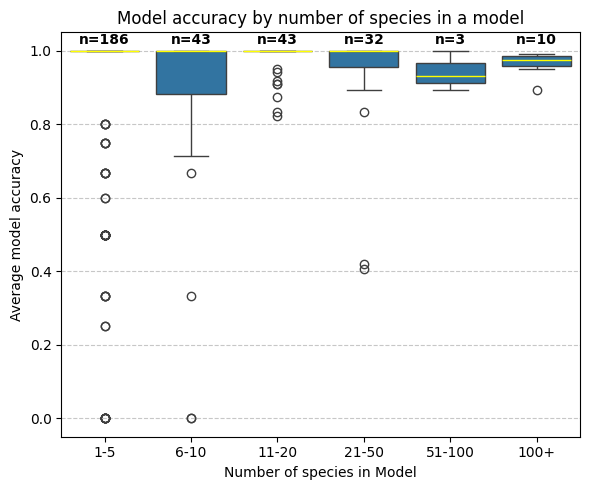

In [24]:
accuracy_by_species_count("results/biomd251106_chebi_rag_llama-4_top10_rerun.csv")

Filtering results by qualifiers: ['is', 'isVersionOf']


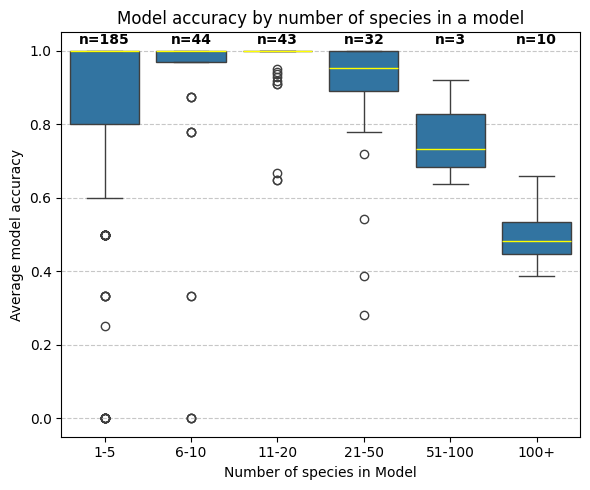

In [25]:
accuracy_by_species_count("results/biomd251106_chebi_rag_llama-4_top10_rrerun.csv")

In [8]:
# fix display name handling
ref_df = pd.read_csv('/Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv')
df = pd.read_csv('/Users/luna/Desktop/CRBM/AMAS_proj/AAAIM/tests/results/biomd_chebi_rag_meta-llama_default.csv')

# Replace 'display_name' in df with 'species_name' from ref_df using 'model' and 'species_id' as keys
df = df.merge(ref_df[['model', 'species_id', 'species_name']], on=['model', 'species_id'], how='left', suffixes=('', '_ref'))
df['display_name'] = df['species_name']
df = df.drop(columns=['species_name'])
df.to_csv('/Users/luna/Desktop/CRBM/AMAS_proj/AAAIM/tests/results/biomd_chebi_rag_meta-llama_default_display_names.csv', index=False)

# Bigg models

In [2]:
model_dir = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggModels"
# Check if model directory exists
if os.path.exists(model_dir):
    model_files = [f for f in os.listdir(model_dir) if f.endswith('.xml')]
    print(f"✓ Model directory found: {model_dir}")
    print(f"  - Found {len(model_files)} XML files")

✓ Model directory found: /Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggModels
  - Found 108 XML files


In [3]:
# Run batch evaluation 
batch_results_df = evaluate_models_in_folder(
    model_dir=model_dir,
    llm_model="gpt-5-mini-2025-08-07",
    method="rag",
    top_k=3,
    entity_type=entity_type,
    database=database,
    save_llm_results=True,
    output_dir=output_dir,
    output_file="bigg_chebi_rag_gpt-5-mini_top3.csv",
    start_at=1,
    verbose=False,
    chunk_size=50
)

Rate limiting enabled: max 10 LLM requests per minute
LLM results will be saved to: ./results/gpt-5-mini-2025-08-07/chemical/20260402_1626
Saved configuration to ./results/gpt-5-mini-2025-08-07/chemical/20260402_1626/config.txt
Evaluating 1/108: RECON1.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/RECON1.txt
Evaluating 2/108: Recon3D.xml
Evaluating 3/108: STM_v1_0.xml
Evaluating 4/108: e_coli_core.xml
Evaluating 5/108: iAB_RBC_283.xml
Evaluating 6/108: iAF1260.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iAF1260.txt
Evaluating 7/108: iAF1260b.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iAF1260b.txt
Evaluating 8/108: iAF692.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iAF692.txt
Evaluating 9/108: iAF987.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iAF987.txt
Evaluating 10/108: iAM_Pb448.xml
LLM results saved to: results

2026-04-02 21:41:22,205 - ERROR - Error loading SBML file with antimony: Unable to read SBML file '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggModels/iAT_PLT_636.xml' due to errors encountered when parsing the file.  Error(s) from libSBML:

line 32: (80601 [Warning]) As a principle of best modeling practice, the <species> should set an initial value (amount or concentration) rather than be left undefined. Doing so improves the portability of models between different simulation and analysis systems, and helps make it easier to detect potential errors in models.
 The <species> with the id 'M_pa_hs_18_2_20_4_c' does not have an 'initialConcentration' or 'initialAmount' attribute, nor is its initial value set by an <initialAssignment> or <assignmentRule>.

line 46: (80601 [Warning]) As a principle of best modeling practice, the <species> should set an initial value (amount or concentration) rather than be left undefined. Doing so improves the portability of models between different simul

LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iAT_PLT_636.txt
Evaluating 17/108: iB21_1397.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iB21_1397.txt
Evaluating 18/108: iBWG_1329.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iBWG_1329.txt
Evaluating 19/108: iCHOv1.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iCHOv1.txt
Evaluating 20/108: iCHOv1_DG44.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iCHOv1_DG44.txt
Evaluating 21/108: iCN718.xml


2026-04-03 00:43:26,794 - ERROR - Error loading SBML file with antimony: Unable to read SBML file '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggModels/iCN718.xml' due to errors encountered when parsing the file.  Error(s) from libSBML:

line 68161: (21101 [Error]) A <reaction> definition must contain at least one <speciesReference>, either in its <listOfReactants> or its <listOfProducts>. A reaction without any reactant or product species is not permitted, regardless of whether the reaction has any modifier species.
Reference: L3V1 Section 4.11.3
 The <reaction> with id 'R_DNADRAIN' does not contain any reactants or products. 


2026-04-03 00:44:11,707 - ERROR - Error loading SBML file with antimony: Unable to read SBML file '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggModels/iCN718.xml' due to errors encountered when parsing the file.  Error(s) from libSBML:

line 68161: (21101 [Error]) A <reaction> definition must contain at least one <speciesReference>, either in its <listOfReact

LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iCN718.txt
Evaluating 22/108: iCN900.xml
API error from OpenAI: Error code: 400 - {'error': {'message': "We could not parse the JSON body of your request. (HINT: This likely means you aren't using your HTTP library correctly. The OpenAI API expects a JSON payload, but what was sent was not valid JSON. If you have trouble figuring out how to fix this, please contact us through our help center at help.openai.com.)", 'type': 'invalid_request_error', 'param': None, 'code': None}}
All retries exhausted for OpenAI. Last error: Error code: 400 - {'error': {'message': "We could not parse the JSON body of your request. (HINT: This likely means you aren't using your HTTP library correctly. The OpenAI API expects a JSON payload, but what was sent was not valid JSON. If you have trouble figuring out how to fix this, please contact us through our help center at help.openai.com.)", 'type': 'invalid_request_error', 'param': No

...

LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iRC1080.txt
Evaluating 88/108: iSB619.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSB619.txt
Evaluating 89/108: iSBO_1134.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSBO_1134.txt
Evaluating 90/108: iSDY_1059.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSDY_1059.txt
Evaluating 91/108: iSFV_1184.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSFV_1184.txt
Evaluating 92/108: iSF_1195.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSF_1195.txt
Evaluating 93/108: iSFxv_1172.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSFxv_1172.txt
Evaluating 94/108: iSSON_1240.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSSON_1240.txt
Evaluating 95/108: iS_1188.xml
LLM results saved to: results/gp

2026-04-04 16:04:17,489 - ERROR - Error loading SBML file with antimony: Unable to read SBML file '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggModels/iSynCJ816.xml' due to errors encountered when parsing the file.  Error(s) from libSBML:

line 62520: (21101 [Error]) A <reaction> definition must contain at least one <speciesReference>, either in its <listOfReactants> or its <listOfProducts>. A reaction without any reactant or product species is not permitted, regardless of whether the reaction has any modifier species.
Reference: L3V1 Section 4.11.3
 The <reaction> with id 'R_DNADRAIN' does not contain any reactants or products. 

line 14: (fbc-20506 [Error]) An <objective> object must have one and only one instance of the <listOfFluxObjectives> object. 
Reference: L3V1 Fbc V3, Section 3.6
 <objective> 'obj' has no listOfFluxObjectives.


2026-04-04 16:05:21,923 - ERROR - Error loading SBML file with antimony: Unable to read SBML file '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggMod

LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iSynCJ816.txt
Evaluating 98/108: iUMN146_1321.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iUMN146_1321.txt
Evaluating 99/108: iUMNK88_1353.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iUMNK88_1353.txt
Evaluating 100/108: iUTI89_1310.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iUTI89_1310.txt
Evaluating 101/108: iWFL_1372.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iWFL_1372.txt
Evaluating 102/108: iY75_1357.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iY75_1357.txt
Evaluating 103/108: iYL1228.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iYL1228.txt
Evaluating 104/108: iYO844.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iYO844.txt
Evaluating 105/108: iYS1720.xml


2026-04-04 19:35:31,936 - ERROR - Error loading SBML file with antimony: Unable to read SBML file '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BiggModels/iYS1720.xml' due to errors encountered when parsing the file.  Error(s) from libSBML:

line 52795: (fbc-20303 [Error]) The value of attribute 'fbc:chemicalFormula' on the SBML <species> object must be set to a string consisting only of atomic names or user defined compounds and their occurrence.
Reference: L3V1 Fbc V3 Section 3.4
 Encountered 'c' when expecting a capital letter. The chemicalFormula 'C2970H5292N202O1896P4charge297' has incorrect syntax.

line 53575: (fbc-20303 [Error]) The value of attribute 'fbc:chemicalFormula' on the SBML <species> object must be set to a string consisting only of atomic names or user defined compounds and their occurrence.
Reference: L3V1 Fbc V3 Section 3.4
 Encountered 'c' when expecting a capital letter. The chemicalFormula 'C870H1542N52O546P4charge72' has incorrect syntax.

line 54771: (fbc-20303 

LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iYS1720.txt
Evaluating 106/108: iYS854.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iYS854.txt
Evaluating 107/108: iZ_1308.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/iZ_1308.txt
Evaluating 108/108: ic_1306.xml
LLM results saved to: results/gpt-5-mini-2025-08-07/chemical/20260402_1626/ic_1306.txt


In [4]:
print_evaluation_results("results/bigg_chebi_rag_gpt-5-mini_top3.csv", ref_results_csv=None)

Showing all results
Number of models assessed: 102
Number of models with predictions: 102
Number of annotations evaluated: 126569
NA rate for synonyms_LLM: 0.004
UNK rate for synonyms_LLM: 0.0
--------------------------------
Per-model statistics:
Average accuracy (per model): 0.97
Ave. recall (formula): 0.96
Ave. precision (formula): 0.695
Ave. recall (exact): 0.315
Ave. precision (exact): 0.558
--------------------------------
Per-species statistics:
Average accuracy (per species): 0.969
Ave. recall (formula, per species): 0.96
Ave. precision (formula, per species): 0.695
Ave. recall (exact, per species): 0.322
Ave. precision (exact, per species): 0.554
--------------------------------
Time:
Ave. total time (per model): 1543.767
Ave. total time (per element, per model): 1.244
Ave. LLM time (per model): 1517.899
Ave. LLM time (per element, per model): 1.223
Average number of predictions per species: 2.94


In [6]:
df = pd.read_csv('results/bigg_chebi_rag_gpt-5-mini_top3.csv')
models = df['model'].unique()
df_prev = pd.read_csv('prev_results/bigg_chebi_rag_llama-3_top3.csv')
models_prev = df_prev['model'].unique()
models_only_in_prev = [model for model in models_prev if model not in models]
print(models_only_in_prev)

['Recon3D.xml', 'STM_v1_0.xml', 'e_coli_core.xml', 'iAB_RBC_283.xml', 'iECDH1ME8569_1439.xml', 'iECD_1391.xml']


In [ ]:
# remove duplicate reasons
input_csv = "results/bigg_chebi_rag_llama-4_top3.csv"
output_path = "results/bigg_chebi_rag_llama-4_top3_deduplicated.csv"

df = pd.read_csv(input_csv)
df_cleaned = df.copy()

# Group by model and keep reason only for the first row of each model
for model_name in df_cleaned['model'].unique():
    model_mask = df_cleaned['model'] == model_name
    model_indices = df_cleaned[model_mask].index
    
    # Keep reason only for the first species in each model
    if len(model_indices) > 1:
        # Set reason to empty string for all but the first row
        df_cleaned.loc[model_indices[1:], 'reason'] = ''

# Save the cleaned CSV
df_cleaned.to_csv(output_path, index=False)

In [ ]:
print_evaluation_results("results/bigg_chebi_rag_llama-3_top3.csv", ref_results_csv=None)

Showing all results
Number of models assessed: 108
Number of models with predictions: 108
Number of annotations evaluated: 133236
Average accuracy (per model): 0.91
Ave. recall (formula): 0.90
Ave. precision (formula): 0.64
Ave. recall (exact): 0.29
Ave. precision (exact): 0.51
Average accuracy (per species): 0.91
Ave. recall (formula, per species): 0.90
Ave. precision (formula, per species): 0.64
Ave. recall (exact, per species): 0.30
Ave. precision (exact, per species): 0.51
Ave. total time (per model): 926.95
Ave. total time (per element, per model): 0.75
Ave. LLM time (per model): 899.51
Ave. LLM time (per element, per model): 0.73
Average number of predictions per species: 2.97


In [ ]:
print_evaluation_results("results/bigg_chebi_rag_llama-4_top3.csv", ref_results_csv=None)

Showing all results
Number of models assessed: 108
Number of models with predictions: 108
Number of annotations evaluated: 133236
Average accuracy (per model): 0.96
Ave. recall (formula): 0.94
Ave. precision (formula): 0.69
Ave. recall (exact): 0.31
Ave. precision (exact): 0.55
Average accuracy (per species): 0.95
Ave. recall (formula, per species): 0.94
Ave. precision (formula, per species): 0.69
Ave. recall (exact, per species): 0.31
Ave. precision (exact, per species): 0.54
Ave. total time (per model): 600.21
Ave. total time (per element, per model): 0.49
Ave. LLM time (per model): 577.79
Ave. LLM time (per element, per model): 0.47
Average number of predictions per species: 2.91


# Larger models

In [15]:
from utils.evaluation import find_models_with_many_species
model_dir = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels"

large_models_df = find_models_with_many_species(
    model_dir=model_dir,
    threshold=50,
    entity_type="chemical",
    database="chebi",
    bqbiol_qualifiers=['is', 'isVersionOf'],
    verbose=True
)

2025-10-28 10:33:33,894 - INFO - Found large model: BIOMD0000000239.xml with 51 species
2025-10-28 10:33:36,860 - INFO - Found large model: BIOMD0000000469.xml with 379 species
2025-10-28 10:33:37,235 - INFO - Found large model: BIOMD0000000470.xml with 379 species
2025-10-28 10:33:37,510 - INFO - Found large model: BIOMD0000000471.xml with 300 species
2025-10-28 10:33:37,897 - INFO - Found large model: BIOMD0000000472.xml with 300 species
2025-10-28 10:33:38,269 - INFO - Found large model: BIOMD0000000473.xml with 310 species
2025-10-28 10:33:39,167 - INFO - Found large model: BIOMD0000000496.xml with 284 species
2025-10-28 10:33:39,495 - INFO - Found large model: BIOMD0000000497.xml with 284 species
2025-10-28 10:33:41,403 - INFO - Found large model: BIOMD0000000579.xml with 132 species
2025-10-28 10:33:42,183 - INFO - Found large model: BIOMD0000000602.xml with 56 species
2025-10-28 10:33:42,611 - INFO - Found large model: BIOMD0000000627.xml with 58 species
2025-10-28 10:33:49,586 

In [ ]:
test_model_file = "/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels/BIOMD0000000579.xml"
result_df = evaluate_single_model(
    model_file=test_model_file,
    llm_model=llm_model,
    method = 'rag',
    top_k = 10,
    entity_type=entity_type,
    database=database,
    save_llm_results=True,
    output_dir=output_dir,
    verbose=True
)

In [ ]:
# results from 

In [ ]:
large_models_df

# LLM synergy

In [3]:
from utils.evaluation import evaluate_llm_synergy

# Compare multiple LLM results
synergy_df = evaluate_llm_synergy(
    'results/biomd_chebi_rag_llama-3_top3_prompt_adjusted.csv',
    'results/biomd_chebi_rag_llama-4_top3_prompt_adjusted.csv',
    output_file='llm_synergy_analysis.csv'
)

Analyzing synergy between 2 LLMs: biomd_chebi_rag_llama-3_top3_prompt_adjusted, biomd_chebi_rag_llama-4_top3_prompt_adjusted
Analysis level: model
Saved synergy analysis to llm_synergy_analysis.csv

=== LLM SYNERGY ANALYSIS SUMMARY (PER-MODEL) ===
Total models analyzed: 340
Average synergy gains:
  Recall: 0.009
  Precision: -0.417
  Accuracy: 0.136

Top 100 models with highest synergy potential (recall):
  BIOMD0000000183.xml (gain: 0.984)
  BIOMD0000000559.xml (gain: 0.975)
  BIOMD0000000153.xml (gain: 0.852)
  BIOMD0000000636.xml (gain: 0.732)
  BIOMD0000000457.xml (gain: 0.731)
  BIOMD0000000453.xml (gain: 0.714)
  BIOMD0000000452.xml (gain: 0.714)
  BIOMD0000000571.xml (gain: 0.684)
  BIOMD0000000399.xml (gain: 0.684)
  BIOMD0000000326.xml (gain: 0.667)

LLM performance distribution:

LLM Complementarity (higher = more diverse):
  Average recall std dev: 0.034
  Average precision std dev: 0.045

Best LLM distribution (by recall):
  biomd_chebi_rag_llama-3_top3_prompt_adjusted: bes

# Save filtered results

In [17]:
print_evaluation_results("/Users/luna/Desktop/CRBM/AMAS_proj/AAAIM/tests/results/biomd_chebi_rag_llama-3_top10_prompt_adjusted.csv", ref_results_csv=None)

Showing all results
Number of models assessed: 340
Number of models with predictions: 338
Number of annotations evaluated: 10771
Average accuracy (per model): 0.81
Ave. recall (formula): 0.80
Ave. precision (formula): 0.19
Ave. recall (exact): 0.75
Ave. precision (exact): 0.08
Average accuracy (per species): 0.40
Ave. recall (formula, per species): 0.40
Ave. precision (formula, per species): 0.10
Ave. recall (exact, per species): 0.32
Ave. precision (exact, per species): 0.04
Ave. total time (per model): 4.54
Ave. total time (per element, per model): 0.14
Ave. LLM time (per model): 4.05
Ave. LLM time (per element, per model): 0.13
Average number of predictions per species: 9.23


In [16]:
results_xlsx = "/Users/luna/Desktop/CRBM/AMAS_proj/AAAIM/tests/results/biomd_chebi_rag_llama-3_top10_prompt_adjusted_review.xlsx"
ref_results_csv = "/Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv"
df = pd.read_excel(results_xlsx)

# Filter by reference results
ref_df = pd.read_csv(ref_results_csv)
ref_pairs = set(zip(ref_df['model'], ref_df['species_id']))
mask = df.apply(lambda row: (row['model'], row['species_id']) in ref_pairs, axis=1)
df = df[mask]

print(f"Filtered results to {len(df)} entries that exist in reference: {ref_results_csv}")

Filtered results to 9650 entries that exist in reference: /Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv


In [ ]:
df.to_excel('results/biomd_chebi_rag_llama-3_top10_prompt_adjusted_is+isVersionOf_review.xlsx', index=False)